# Temporal Analysis: Where Does the Class Information Live?

The central efficiency claim of this thesis is that a recurrent network does not
need to observe an entire sequence to classify it: stopping the recurrence at a timestep
$k < T$ saves latency and dynamic energy proportionally. Before any spiking model
is trained under such a cutoff, one question must be settled based on the data
alone. If a truncated network scores well at $k = 0.2\,T$, is that evidence that
the *architecture* tolerates truncation, or merely that the *dataset* was already
separable that early?

This notebook establishes the data-side reference against which the model-side
$k$-sweep of Chapter 5 is read. Two complementary views are computed:

1. **Per-timestep separability.** A one-way ANOVA $F$-statistic computed
   independently at each timestep, measuring how far the class means are apart
   relative to the within-class spread. This view is *marginal*: it localizes the
   discriminative region of the waveform but is blind to information distributed
   jointly across timesteps.
2. **Prefix-classifier performance.** A linear probe fit on the truncated prefix
   $x_{1:k}$ for each $k$ on the truncation grid, scored by cross-validated
   Macro-F1. This view is *cumulative*, and because the probe is linear it is a
   conservative lower bound on the label information recoverable from the first
   $k$ samples.

Both analyses run on the **training split only**, and the prefix curve is
cross-validated within it. The truncation point $k$ is a headline hyperparameter
of this work; selecting or even inspecting it against the test split would leak
the test set into that choice and invalidate every accuracy reported later.

In [1]:
import pandas as pd

from edgesnn.data_utils import make_datasets
from edgesnn.plotting import plot_prefix_curve, plot_separability
from edgesnn.temporal_analysis import (
    FRACTION_GRID,
    earliest_k_within,
    k_grid,
    per_timestep_f_statistic,
    prefix_classifier_curve,
)

In [2]:
DATA_DIR = "../Data"
FIG_DIR = "../reports/figures"
DATASETS = ["ECG5000", "Wafer", "InsectSound"]
SEED = 0

print("Truncation grid (fractions of T):", FRACTION_GRID)

Truncation grid (fractions of T): (0.2, 0.4, 0.6, 0.8, 1.0)


## 1. Loading the training splits




`make_datasets` returns the preprocessing pipeline described in Section 3.2 in
full: ECG5000's five original classes aggregated to a binary normal/abnormal
problem, Wafer's $\{-1, 1\}$ labels re-encoded to $\{0, 1\}$, InsectSound's ten
species names mapped to integers, and a global $z$-score normalization whose
statistics are fit on the training split alone. The analysis below therefore
operates on exactly the tensors the networks will be trained on, not on the raw
archive files. Only the training split is retained here.

In [3]:
train_splits = {}
for name in DATASETS:
    train_ds, _ = make_datasets(DATA_DIR, name)
    train_splits[name] = train_ds
    print(f"{name:<12} N={len(train_ds):>6}  T={train_ds.seq_len:>4}  "
          f"C={train_ds.num_classes}  k-grid={k_grid(train_ds.seq_len)}")

ECG5000      N=   500  T= 140  C=2  k-grid=[28, 56, 84, 112, 140]
Wafer        N=  1000  T= 152  C=2  k-grid=[30, 61, 91, 122, 152]
InsectSound  N= 25000  T= 600  C=10  k-grid=[120, 240, 360, 480, 600]


## 2. Per-timestep class separability

For each timestep $t$ the samples are partitioned by class and the one-way ANOVA
statistic

$$F_t = \frac{\mathrm{SS}_\mathrm{between}(t) / (C-1)}{\mathrm{SS}_\mathrm{within}(t) / (N-C)}$$

is evaluated, where $\mathrm{SS}_\mathrm{between}$ is the scatter of the per-class
means about the grand mean and $\mathrm{SS}_\mathrm{within}$ the pooled scatter
within classes. The raw statistic is reported rather than a $p$-value: with $T$ up
to 600 the per-timestep hypothesis tests would require a multiple-comparison
correction to be interpretable, whereas the curve is read for its shape — where
along the sequence the discriminative mass accumulates — rather than for
significance at any single timestep. The dashed vertical lines mark the
truncation grid, so the area discarded by each cutoff can be read directly.

[plot] saved ../reports/figures/ECG5000_separability.png


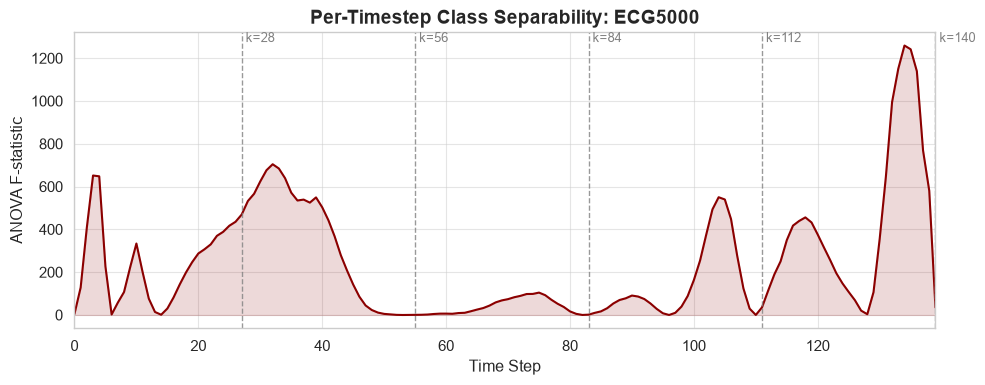

[plot] saved ../reports/figures/Wafer_separability.png


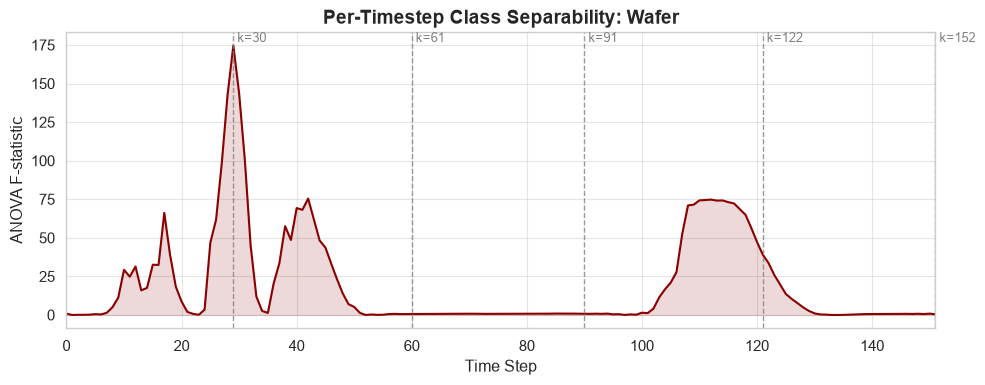

[plot] saved ../reports/figures/InsectSound_separability.png


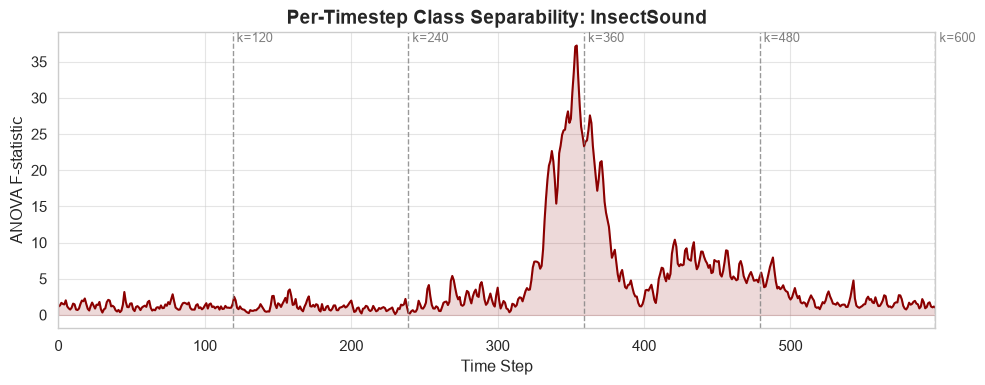

In [4]:
f_stats = {}
for name, ds in train_splits.items():
    f_stats[name] = per_timestep_f_statistic(ds.x, ds.y)
    plot_separability(
        f_stats[name],
        dataset_name=name,
        k_marks=k_grid(ds.seq_len),
        save_path=f"{FIG_DIR}/{name}_separability.png",
    )

To summarize each curve in a form that can be tabulated, the cumulative share of

the total separability mass $\sum_t F_t$ falling before each truncation point is
reported below. It quantifies, per dataset, how much marginal discriminative
signal a given cutoff discards.

In [5]:
rows = []
for name, f in f_stats.items():
    total = f.sum()
    row = {"dataset": name, "peak timestep": int(f.argmax())}
    for k in k_grid(len(f)):
        row[f"{k / len(f):.0%}"] = f[:k].sum() / total
    rows.append(row)

mass = pd.DataFrame(rows).set_index("dataset")
mass.style.format({c: "{:.1%}" for c in mass.columns if c.endswith("%")})

,peak timestep,20%,40%,60%,80%,100%
dataset,,,,,,
ECG5000,134,20.2%,47.8%,51.1%,63.1%,100.0%
Wafer,29,28.7%,59.2%,60.0%,95.7%,100.0%
InsectSound,354,6.1%,11.6%,49.7%,88.9%,100.0%


## 3. Prefix-classifier performance

The $F$-statistic treats each timestep in isolation, so it cannot detect class
information carried by the *relationship* between timesteps — precisely the kind
of information a recurrent model exists to exploit. The cumulative view is
therefore obtained with a classifier restricted to the prefix.

For each $k$ on the truncation grid, the samples are truncated to their first $k$
timesteps, standardized, and passed to a multinomial logistic regression
evaluated by stratified five-fold cross-validation within the training split.
Macro-F1 is the score, since Wafer and ECG5000 are strongly imbalanced and
accuracy would be dominated by the majority class; stratification guarantees the
minority class is represented in every fold.

The probe is deliberately linear and deliberately model-free. It carries no
recurrence, no temporal inductive bias and no capacity to be credited for the
architectural contributions of this thesis, which makes its curve a floor rather
than a competitor: any margin the spiking reservoir holds over it at the same $k$
is attributable to the model, while a prefix curve that is already flat at
$k = 0.2\,T$ indicates that the dataset itself permits early classification.

In [6]:
curves = {}
for name, ds in train_splits.items():
    print(f"{name} (N={len(ds)}, T={ds.seq_len}):")
    curves[name] = prefix_classifier_curve(ds.x, ds.y, seed=SEED, verbose=True)

ECG5000 (N=500, T=140):
  k=  28 (20.0%)  macro-F1 0.9773 +/- 0.0121
  k=  56 (40.0%)  macro-F1 0.9773 +/- 0.0042
  k=  84 (60.0%)  macro-F1 0.9814 +/- 0.0077
  k= 112 (80.0%)  macro-F1 0.9835 +/- 0.0082
  k= 140 (100.0%)  macro-F1 0.9856 +/- 0.0105
Wafer (N=1000, T=152):
  k=  30 (19.7%)  macro-F1 0.7894 +/- 0.0513
  k=  61 (40.1%)  macro-F1 0.8213 +/- 0.0396
  k=  91 (59.9%)  macro-F1 0.8298 +/- 0.0389
  k= 122 (80.3%)  macro-F1 0.8370 +/- 0.0408
  k= 152 (100.0%)  macro-F1 0.8461 +/- 0.0363
InsectSound (N=25000, T=600):
  k= 120 (20.0%)  macro-F1 0.1213 +/- 0.0043
  k= 240 (40.0%)  macro-F1 0.1532 +/- 0.0028
  k= 360 (60.0%)  macro-F1 0.1951 +/- 0.0055
  k= 480 (80.0%)  macro-F1 0.2080 +/- 0.0037
  k= 600 (100.0%)  macro-F1 0.2075 +/- 0.0027


[plot] saved ../reports/figures/prefix_classifier_curves.png


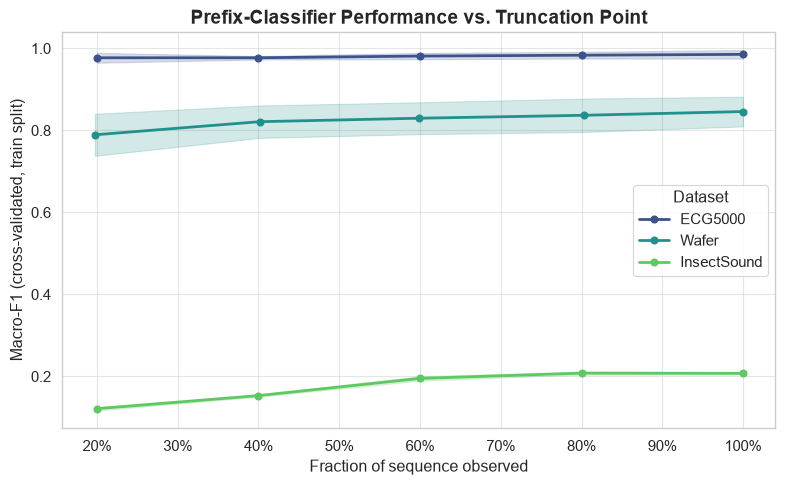

<Axes: title={'center': 'Prefix-Classifier Performance vs. Truncation Point'}, xlabel='Fraction of sequence observed', ylabel='Macro-F1 (cross-validated, train split)'>

In [7]:
plot_prefix_curve(curves, save_path=f"{FIG_DIR}/prefix_classifier_curves.png")

## 4. The earliest sufficient cutoff

Each curve is reduced to a single figure: the smallest $k$ whose cross-validated
Macro-F1 lies within one percentage point of the best score that dataset attains
at any cutoff. This is the point beyond which additional timesteps buy
essentially nothing, and it forms the data-side prediction that the model-side
$k$-sweep will be compared against.

In [8]:
summary = pd.DataFrame([
    dict(zip(["dataset", "k", "fraction of T", "macro-F1"],
             (name, *earliest_k_within(curve, tolerance=0.01))))
    for name, curve in curves.items()
]).set_index("dataset")
summary

,k,fraction of T,macro-F1
dataset,,,
ECG5000,28,0.200000,0.977255
Wafer,122,0.802632,0.836968
InsectSound,480,0.800000,0.208021


## 5. Consequences for the truncation study

Three observations carry forward into the experimental design.

First, the marginal and cumulative views need not agree, and where they diverge
the divergence is itself informative. A dataset whose $F$-statistic peaks late in
the sequence yet whose prefix classifier saturates early is one in which the most
*individually* discriminative timesteps are redundant given what the earlier ones
already jointly determine — exactly the redundancy a truncated model is intended
to exploit.

Second, the absolute level of the prefix curve calibrates how much of the
eventual result is attributable to the architecture. Where a linear probe on raw
amplitudes already approaches the ceiling, the classification problem is close to
trivial and no architecture should claim credit for solving it; where the probe
remains far above chance but far below the ceiling, the margin left for a
recurrent model is real and measurable.

Third, these curves are computed without reference to any spiking model, so they
remain a valid control regardless of how the reservoir is initialized or trained.
The same grid of cutoffs is applied to the LSTM baseline in Chapter 4 for the
same reason: a flat accuracy-versus-$k$ curve for the spiking network is only
evidence of graceful truncation if the dense baseline and the model-free probe do
not exhibit the identical shape.

The figures written by this notebook are `<dataset>_separability.png` and
`prefix_classifier_curves.png` in `reports/figures/`. The protocol above is
described in Section 3.7; the curves themselves are discussed in the results.